<a href="https://colab.research.google.com/github/sumitgiri35885-rgb/Time-Series-Forcasting/blob/main/Time_Series_Forcasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving AirPassengers.csv to AirPassengers.csv


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('AirPassengers.csv')
df.head()

,Month,Passengers
0,15-01-1949,112
1,15-02-1949,118
2,15-03-1949,132
3,15-04-1949,129
4,15-05-1949,121


In [ ]:
df.tail(5)

,Month,Passengers
139,15-08-1960,606
140,15-09-1960,508
141,15-10-1960,461
142,15-11-1960,390
143,15-12-1960,432


In [ ]:
df.isnull()

,Month,Passengers
0,False,False
1,False,False
2,False,False
3,False,False
4,False,False
...,...,...
139,False,False
140,False,False
141,False,False
142,False,False


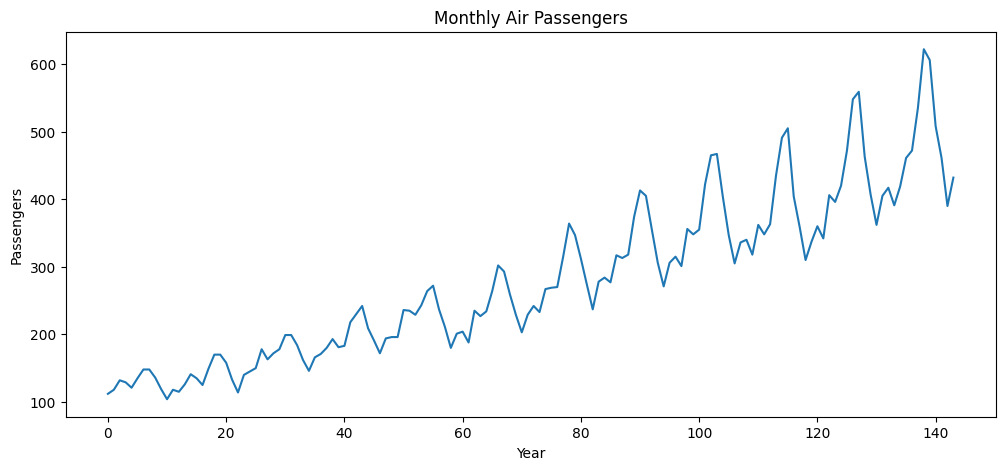

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(df['Passengers'])
plt.title("Monthly Air Passengers")
plt.xlabel("Year")
plt.ylabel("Passengers")
plt.show()

In [ ]:
import pandas as pd

df = pd.read_csv('AirPassengers.csv')

# Rename only value column
df.rename(columns={'value': 'Passengers'}, inplace=True)

print(df.head())

        Month  Passengers
0  15-01-1949         112
1  15-02-1949         118
2  15-03-1949         132
3  15-04-1949         129
4  15-05-1949         121


In [ ]:
print(df.columns)

Index(['Month', 'Passengers'], dtype='object')


In [ ]:
#Create Features from Date

df['Year'] = df.index.year
df['Month'] = df.index.month

df.head()

,Passengers,Year,Month_Num,Month
Month,,,,
1949-01-15,112,1949,1,1
1949-02-15,118,1949,2,2
1949-03-15,132,1949,3,3
1949-04-15,129,1949,4,4
1949-05-15,121,1949,5,5


In [ ]:
# Convert Month column to datetime
df['Month'] = pd.to_datetime(df['Month'])

# Set Month as index
df.set_index('Month', inplace=True)

# Create features
df['Year'] = df.index.year
df['Month_Num'] = df.index.month

df.head()

/tmp/ipykernel_3207/1019627631.py:2: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Month'] = pd.to_datetime(df['Month'])


,Passengers,Year,Month_Num
Month,,,
1949-01-15,112,1949,1
1949-02-15,118,1949,2
1949-03-15,132,1949,3
1949-04-15,129,1949,4
1949-05-15,121,1949,5


In [ ]:
#Define Features and Target
X = df[['Year', 'Month']]
y = df['Passengers']

In [ ]:
#Train-Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
#Train Random Forest Model
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [ ]:
#Predictions
y_pred = model.predict(X_test)

In [ ]:
#Evaluate Model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE : 14.032758620689652
RMSE: 17.979348977512295
R² Score: 0.9674703116523091


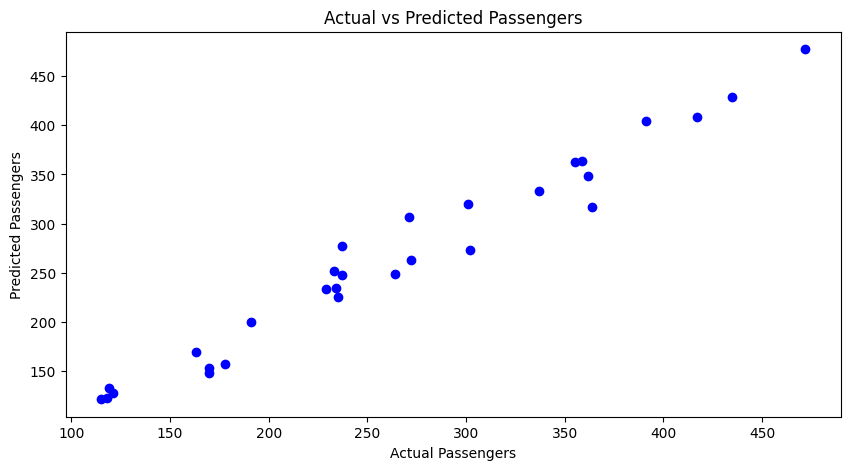

In [ ]:
#Actual vs Predicted
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.scatter(y_test, y_pred, color='blue')

plt.xlabel("Actual Passengers")
plt.ylabel("Predicted Passengers")
plt.title("Actual vs Predicted Passengers")

plt.show()

In [ ]:
#Predict Future Passengers
future = pd.DataFrame({
    'Year': [1961]*12,
    'Month': [1,2,3,4,5,6,7,8,9,10,11,12]
})

future_predictions = model.predict(future)

future['Predicted Passengers'] = future_predictions

print(future)

    Year  Month  Predicted Passengers
0   1961      1                408.85
1   1961      2                404.11
2   1961      3                427.97
3   1961      4                453.10
4   1961      5                468.90
5   1961      6                520.20
6   1961      7                605.07
7   1961      8                606.91
8   1961      9                519.95
9   1961     10                457.83
10  1961     11                406.99
11  1961     12                427.57


In [ ]:
!pip install statsmodels


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error


In [ ]:
#Train-Test Split
train = df.iloc[:-24]
test = df.iloc[-24:]

print("Train Shape:", train.shape)
print("Test Shape:", test.shape)

Train Shape: (120, 4)
Test Shape: (24, 4)


In [ ]:
#Build SARIMA Model
model = SARIMAX(
    train['Passengers'],
    order=(1,1,1),
    seasonal_order=(1,1,1,12)
)

sarima_model = model.fit()

print(sarima_model.summary())


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  120
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -398.830
Date:                            Sun, 18 Oct 2026   AIC                            807.660
Time:                                    13:22:46   BIC                            821.024
Sample:                                         0   HQIC                           813.078
                                            - 120                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4901      0.351     -1.397      0.162      -1.178       0.197
ma.L1          0.2579      0.373   

In [ ]:
#Forecast Test Data
forecast = sarima_model.forecast(
    steps=len(test)
)

In [ ]:
print(df.index)
print(type(df.index))

DatetimeIndex(['1949-02-01', '1949-03-01', '1949-04-01', '1949-05-01',
               '1949-06-01', '1949-07-01', '1949-08-01', '1949-09-01',
               '1949-10-01', '1949-11-01',
               ...
               '1960-03-01', '1960-04-01', '1960-05-01', '1960-06-01',
               '1960-07-01', '1960-08-01', '1960-09-01', '1960-10-01',
               '1960-11-01', '1960-12-01'],
              dtype='datetime64[ns]', name='Month', length=143, freq='MS')
<class 'pandas.core.indexes.datetimes.DatetimeIndex'>


In [ ]:
# Train-Test Split
train = df.iloc[:-12]
test = df.iloc[-12:]

from statsmodels.tsa.statespace.sarimax import SARIMAX

# Build Model
model = SARIMAX(
    train['Passengers'],
    order=(1,1,1),
    seasonal_order=(1,1,1,12)
)

# Fit Model
sarima_model = model.fit()

# Forecast
forecast = sarima_model.get_forecast(
    steps=len(test)
).predicted_mean

print(forecast)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:989: EstimationWarning: Too few observations to estimate starting parameters for ARMA and trend. All parameters except for variances will be set to zeros.
  params_variance) = self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


1960-01-01    0.0
1960-02-01    0.0
1960-03-01    0.0
1960-04-01    0.0
1960-05-01    0.0
1960-06-01    0.0
1960-07-01    0.0
1960-08-01    0.0
1960-09-01    0.0
1960-10-01    0.0
1960-11-01    0.0
1960-12-01    0.0
Freq: MS, Name: predicted_mean, dtype: float64


In [ ]:
print(df.index)
print(type(df.index))
print(df.index.freq)

DatetimeIndex(['1949-02-01', '1949-03-01', '1949-04-01', '1949-05-01',
               '1949-06-01', '1949-07-01', '1949-08-01', '1949-09-01',
               '1949-10-01', '1949-11-01',
               ...
               '1960-03-01', '1960-04-01', '1960-05-01', '1960-06-01',
               '1960-07-01', '1960-08-01', '1960-09-01', '1960-10-01',
               '1960-11-01', '1960-12-01'],
              dtype='datetime64[ns]', name='Month', length=143, freq='MS')
<class 'pandas.core.indexes.datetimes.DatetimeIndex'>
<MonthBegin>


In [ ]:
df = df.asfreq('MS')

In [ ]:
df.index = pd.date_range(
    start='1949-01-01',
    periods=len(df),
    freq='MS'
)

In [ ]:
print(df.index.freq)

<MonthBegin>


In [ ]:
train = df.iloc[:-24]
test = df.iloc[-24:]

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_model = SARIMAX(
    train['Passengers'],
    order=(1,1,1),
    seasonal_order=(1,1,1,12)
).fit()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:989: EstimationWarning: Too few observations to estimate starting parameters for ARMA and trend. All parameters except for variances will be set to zeros.
  params_variance) = self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


In [ ]:
forecast = sarima_model.forecast(
    steps=len(test)
)

print(forecast.head())

1958-12-01    0.0
1959-01-01    0.0
1959-02-01    0.0
1959-03-01    0.0
1959-04-01    0.0
Freq: MS, Name: predicted_mean, dtype: float64


In [ ]:
forecast = sarima_model.predict(
    start=len(train),
    end=len(train)+len(test)-1
)

In [ ]:
df.index = pd.date_range(
    start='1949-01-01',
    periods=len(df),
    freq='MS'
)

train = df.iloc[:-24]
test = df.iloc[-24:]

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_model = SARIMAX(
    train['Passengers'],
    order=(1,1,1),
    seasonal_order=(1,1,1,12)
).fit()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:989: EstimationWarning: Too few observations to estimate starting parameters for ARMA and trend. All parameters except for variances will be set to zeros.
  params_variance) = self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


In [ ]:
forecast = sarima_model.forecast(
    steps=len(test)
)

forecast

,predicted_mean
1958-12-01,0.0
1959-01-01,0.0
1959-02-01,0.0
1959-03-01,0.0
1959-04-01,0.0
1959-05-01,0.0
1959-06-01,0.0
1959-07-01,0.0
1959-08-01,0.0
1959-09-01,0.0


In [ ]:
#Actual vs Predicted
results = pd.DataFrame({
    'Actual': test['Passengers'],
    'Predicted': forecast
})

print(results.head())

            Actual  Predicted
1958-12-01     NaN        0.0
1959-01-01     NaN        0.0
1959-02-01     NaN        0.0
1959-03-01     NaN        0.0
1959-04-01     NaN        0.0


In [5]:
#Plot Results
plt.figure(figsize=(12,6))

plt.plot(
    train.index,
    train['Passengers'],
    label='Train'
)

plt.plot(
    test.index,
    test['Passengers'],
    label='Actual'
)

plt.plot(
    test.index,
    forecast,
    color='red',
    label='SARIMA Forecast'
)

plt.title('SARIMA Forecast vs Actual')
plt.xlabel('Date')
plt.ylabel('Passengers')
plt.legend()

plt.show()

NameError: name 'train' is not defined

<Figure size 1200x600 with 0 Axes>

In [ ]:
#Forecast Future 12 Months
future_forecast = sarima_model.forecast(
    steps=12
)

print(future_forecast)

120    342.279140
121    320.435764
122    366.255216
123    353.324480
124    367.592212
125    437.482347
126    493.549299
127    506.824181
128    408.200234
129    362.348294
130    312.631240
131    339.852245
Name: predicted_mean, dtype: float64


In [ ]:
#Create Future Dates
future_dates = pd.date_range(
    start='1961-01-01',
    periods=12,
    freq='MS'
)

In [ ]:
# Forecast next 12 months
future_forecast = sarima_model.get_forecast(
    steps=12
).predicted_mean

print(future_forecast)

1958-12-01    0.0
1959-01-01    0.0
1959-02-01    0.0
1959-03-01    0.0
1959-04-01    0.0
1959-05-01    0.0
1959-06-01    0.0
1959-07-01    0.0
1959-08-01    0.0
1959-09-01    0.0
1959-10-01    0.0
1959-11-01    0.0
Freq: MS, Name: predicted_mean, dtype: float64


In [ ]:
future_dates = pd.date_range(
    start=df.index[-1] + pd.DateOffset(months=1),
    periods=12,
    freq='MS'
)

print(future_dates)

DatetimeIndex(['1960-12-01', '1961-01-01', '1961-02-01', '1961-03-01',
               '1961-04-01', '1961-05-01', '1961-06-01', '1961-07-01',
               '1961-08-01', '1961-09-01', '1961-10-01', '1961-11-01'],
              dtype='datetime64[ns]', freq='MS')


<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

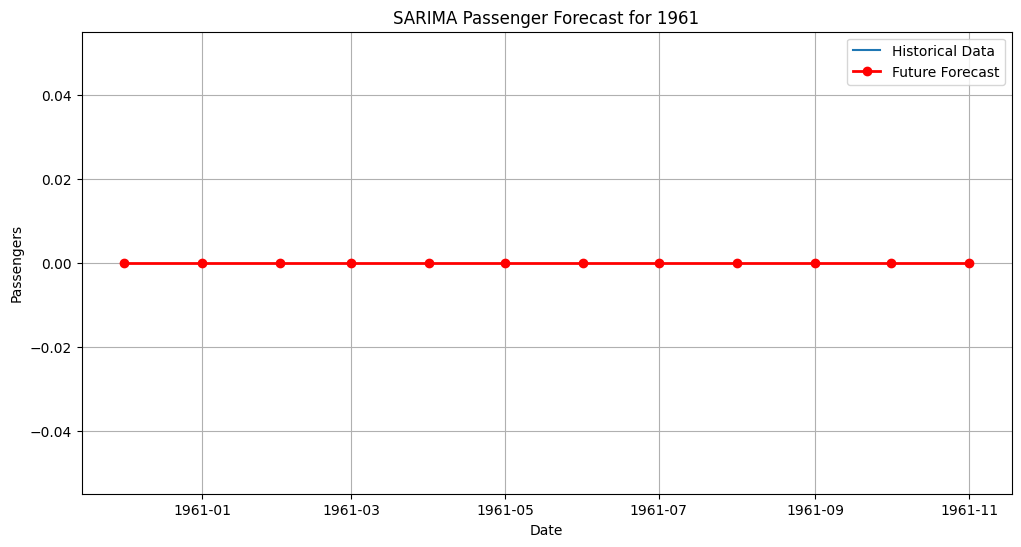

In [ ]:
#Plot Future Forecast
plt.figure(figsize=(12,6))

plt.plot(
    df.index,
    df['Passengers'],
    label='Historical Data'
)

plt.plot(
    future_dates,
    future_forecast,
    color='red',
    marker='o',
    linewidth=2,
    label='Future Forecast'
)

plt.title('SARIMA Passenger Forecast for 1961')
plt.xlabel('Date')
plt.ylabel('Passengers')
plt.legend()

plt.grid(True)

plt

In [ ]:
#Save Forecast
future_df = pd.DataFrame({
    'Date': future_dates,
    'Forecast_Passengers': future_forecast
})

future_df.to_csv(
    'SARIMA_Forecast.csv',
    index=False
)

print(future_df)

                 Date  Forecast_Passengers
1958-12-01 1960-12-01                  0.0
1959-01-01 1961-01-01                  0.0
1959-02-01 1961-02-01                  0.0
1959-03-01 1961-03-01                  0.0
1959-04-01 1961-04-01                  0.0
1959-05-01 1961-05-01                  0.0
1959-06-01 1961-06-01                  0.0
1959-07-01 1961-07-01                  0.0
1959-08-01 1961-08-01                  0.0
1959-09-01 1961-09-01                  0.0
1959-10-01 1961-10-01                  0.0
1959-11-01 1961-11-01                  0.0


In [ ]:
#Confidence Intervals (Advanced)
pred = sarima_model.get_forecast(steps=12)

forecast_mean = pred.predicted_mean
confidence_intervals = pred.conf_int()

print(confidence_intervals)

            lower Passengers  upper Passengers
1958-12-01     -67923.558440      67923.558440
1959-01-01     -68514.822420      68514.822420
1959-02-01     -69101.027426      69101.027426
1959-03-01     -69682.301134      69682.301134
1959-04-01     -70258.765940      70258.765940
1959-05-01     -70830.539257      70830.539257
1959-06-01     -71397.733798      71397.733798
1959-07-01     -71960.457833      71960.457833
1959-08-01     -72518.815432      72518.815432
1959-09-01     -73072.906687      73072.906687
1959-10-01     -73622.827925      73622.827925
1959-11-01     -74168.671902      74168.671902


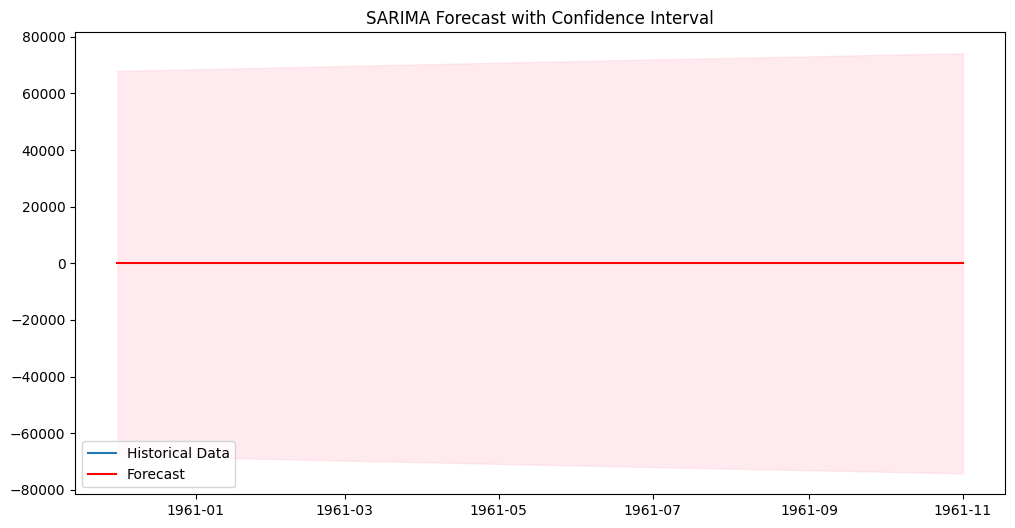

In [ ]:
#Plot Forecast with Confidence Interval
plt.figure(figsize=(12,6))

plt.plot(
    df.index,
    df['Passengers'],
    label='Historical Data'
)

plt.plot(
    future_dates,
    forecast_mean,
    color='red',
    label='Forecast'
)

plt.fill_between(
    future_dates,
    confidence_intervals.iloc[:, 0],
    confidence_intervals.iloc[:, 1],
    color='pink',
    alpha=0.3
)

plt.legend()
plt.title('SARIMA Forecast with Confidence Interval')
plt.show()

In [ ]:
!pwd
!ls -la

/content
total 24
drwxr-xr-x 1 root root 4096 Oct 18 13:31 .
drwxr-xr-x 1 root root 4096 Oct 18 13:05 ..
-rw-r--r-- 1 root root 2322 Oct 18 13:20 AirPassengers.csv
drwxr-xr-x 4 root root 4096 Oct  2 13:50 .config
drwxr-xr-x 1 root root 4096 Oct  2 13:50 sample_data
-rw-r--r-- 1 root root  205 Oct 18 13:31 SARIMA_Forecast.csv
